I_cm=9.500000000000002, M d^2=20.000000000000004, I_new=29.5, check=29.500000000000007
saved the figure


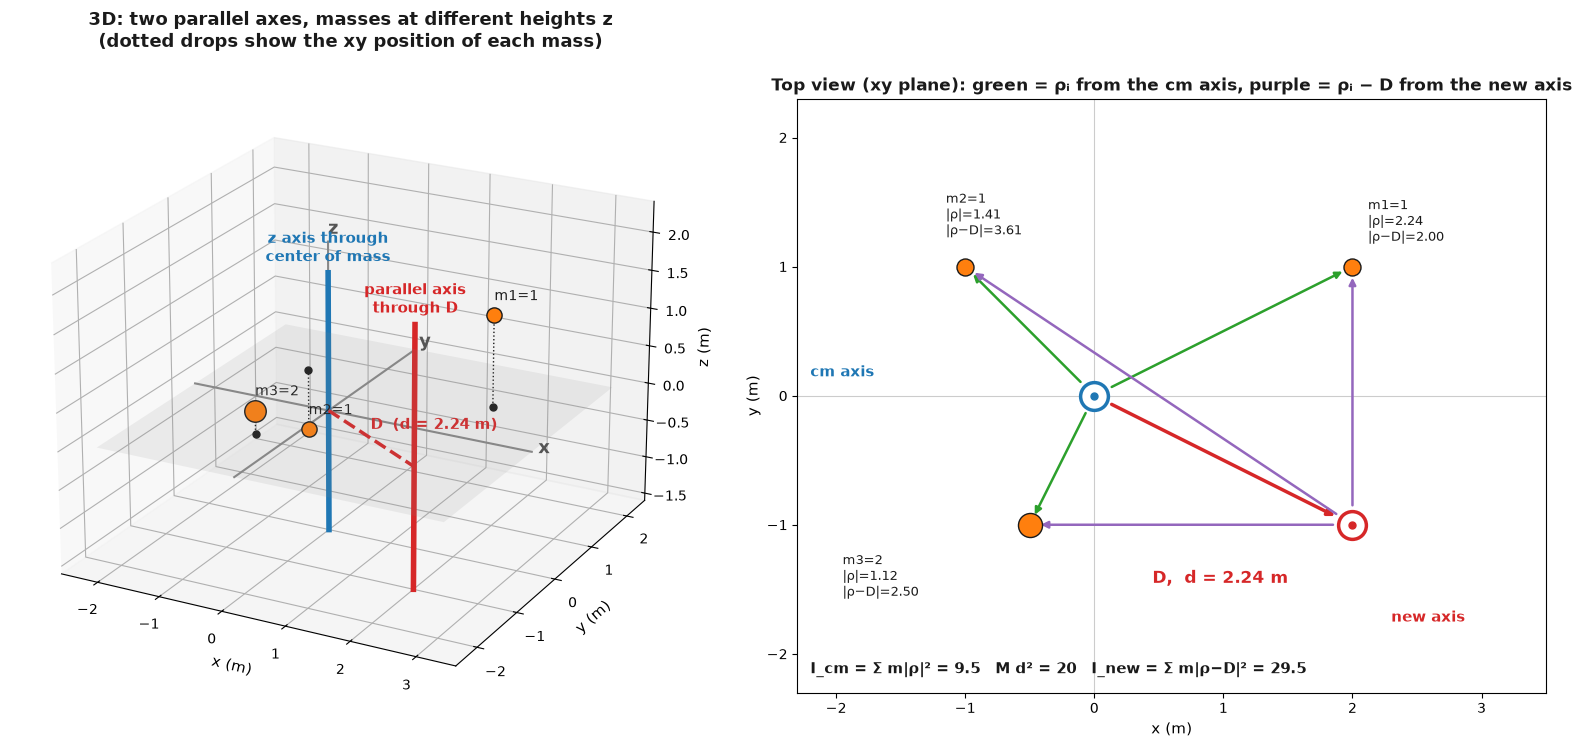

In [3]:
import os
from datetime import datetime
import numpy as np  # type: ignore
import matplotlib.pyplot as plt  # type: ignore

RESULT_DIR = os.path.join(os.getcwd(), "result")
os.makedirs(RESULT_DIR, exist_ok=True)
TIMESTAMP = datetime.now().strftime("%Y%m%d_%H%M%S")

# STEP 1: Define the body (3 masses at different heights z) and the two axes
# What we have: masses m_i at (x_i, y_i, z_i), center of mass at the origin
# What we want: see the setup in 3D and in the xy plane
# Why: only (x_i, y_i) sets the distance to a z-parallel axis, z_i does not matter
# Formula: sum m_i (x_i, y_i) = 0 so the origin is the center of mass (in xy)
m = np.array([1.0, 1.0, 2.0])
xy = np.array([[2.0, 1.0], [-1.0, 1.0], [-0.5, -1.0]])
z = np.array([1.2, -0.8, 0.3])
D = np.array([2.0, -1.0])
assert np.allclose((m[:, None] * xy).sum(axis=0), 0)

# STEP 2: Distances to each axis
# What we have: xy, D
# What we want: r_cm_i = |rho_i| and r_new_i = |rho_i - D|
# Why: these are the lever arms squared in I = sum m r^2
r_cm = np.linalg.norm(xy, axis=1)
r_new = np.linalg.norm(xy - D, axis=1)
M, d = m.sum(), np.linalg.norm(D)
I_cm = (m * r_cm ** 2).sum()
I_new = (m * r_new ** 2).sum()
print(f"I_cm={I_cm}, M d^2={M*d**2}, I_new={I_new}, check={I_cm + M*d**2}")

INK = "#1a1a1a"
C_CM, C_NEW, C_RHO, C_REL, C_M = "#1f77b4", "#d62728", "#2ca02c", "#9467bd", "#ff7f0e"
fig = plt.figure(figsize=(16, 7.5))

# STEP 3: 3D view of the whole setup
# What we have: masses at different heights, two vertical axes
# What we want: see that both axes are parallel to z and that heights do not change distances
# Why: justifies using only the xy plane afterwards
a3 = fig.add_subplot(1, 2, 1, projection="3d")
zmin, zmax = -1.6, 1.8
gx, gy = np.meshgrid(np.linspace(-2.2, 3.2, 2), np.linspace(-2.2, 2.2, 2))
a3.plot_surface(gx, gy, np.zeros_like(gx), alpha=0.12, color="#888888", shade=False)
a3.plot([-2.2, 3.2], [0, 0], [0, 0], color="#888888", lw=1.5)
a3.plot([0, 0], [-2.2, 2.2], [0, 0], color="#888888", lw=1.5)
a3.plot([0, 0], [0, 0], [zmin, zmax + 0.4], color="#888888", lw=1.5)
a3.text(3.3, 0, 0, "x", color="#555555", fontsize=13, fontweight="bold")
a3.text(0, 2.3, 0, "y", color="#555555", fontsize=13, fontweight="bold")
a3.text(0, 0, zmax + 0.5, "z", color="#555555", fontsize=13, fontweight="bold")
a3.plot([0, 0], [0, 0], [zmin, zmax], color=C_CM, lw=4)
a3.plot([D[0], D[0]], [D[1], D[1]], [zmin, zmax], color=C_NEW, lw=4)
a3.text(0, 0, zmax + 0.15, "z axis through\ncenter of mass", color=C_CM, fontsize=11, fontweight="bold", ha="center")
a3.text(D[0], D[1], zmax + 0.15, "parallel axis\nthrough D", color=C_NEW, fontsize=11, fontweight="bold", ha="center")
a3.plot([0, D[0]], [0, D[1]], [0, 0], color=C_NEW, lw=2.5, ls="--")
a3.text(1.0, -0.5, 0.12, "D  (d = %.2f m)" % d, color=C_NEW, fontsize=11, fontweight="bold")
for i in range(3):
    a3.scatter(*xy[i], z[i], s=120 * m[i], color=C_M, edgecolor=INK, depthshade=False, zorder=5)
    a3.plot([xy[i, 0]] * 2, [xy[i, 1]] * 2, [0, z[i]], color=INK, lw=1, ls=":")
    a3.scatter(*xy[i], 0, s=25, color=INK)
    a3.text(xy[i, 0], xy[i, 1], z[i] + 0.2, f"m{i+1}={m[i]:g}", fontsize=10, color=INK)
a3.set_xlabel("x (m)", fontsize=11)
a3.set_ylabel("y (m)", fontsize=11)
a3.set_zlabel("z (m)", fontsize=11)
a3.set_zlim(zmin, zmax + 0.6)
a3.view_init(elev=22, azim=-62)
a3.set_title("3D: two parallel axes, masses at different heights z\n(dotted drops show the xy position of each mass)",
             fontsize=13, fontweight="bold", color=INK)

# STEP 4: Top view in the xy plane with every lever arm
# What we have: xy positions, both axes as points
# What we want: all rho_i and rho_i - D with their lengths
# Why: I_cm = sum m |rho_i|^2 and I_new = sum m |rho_i - D|^2
ax = fig.add_subplot(1, 2, 2)
ax.set_aspect("equal")
ax.set_xlim(-2.3, 3.5)
ax.set_ylim(-2.3, 2.3)
ax.axhline(0, color="#cccccc", lw=0.8)
ax.axvline(0, color="#cccccc", lw=0.8)
for P, c in ((np.zeros(2), C_CM), (D, C_NEW)):
    ax.plot(*P, "o", ms=20, mfc="white", mec=c, mew=2.5, zorder=3)
    ax.plot(*P, "o", ms=5, color=c, zorder=4)
ax.annotate("", xy=D, xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=C_NEW, lw=2.5, shrinkA=14, shrinkB=14))
ax.text(0.45, -1.45, "D,  d = %.2f m" % d, color=C_NEW, fontsize=12, fontweight="bold")
ax.text(-2.2, 0.15, "cm axis", color=C_CM, fontsize=11, fontweight="bold")
ax.text(2.3, -1.75, "new axis", color=C_NEW, fontsize=11, fontweight="bold")
for i in range(3):
    p = xy[i]
    ax.annotate("", xy=p, xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=C_RHO, lw=1.8, shrinkA=14, shrinkB=8))
    ax.annotate("", xy=p, xytext=D, arrowprops=dict(arrowstyle="-|>", color=C_REL, lw=1.8, shrinkA=14, shrinkB=8))
    ax.scatter(*p, s=150 * m[i], color=C_M, edgecolor=INK, zorder=5)
    off = [(0.12, 0.2), (-0.15, 0.25), (-1.45, -0.55)][i]
    ax.text(p[0] + off[0], p[1] + off[1],
            f"m{i+1}={m[i]:g}\n|ρ|={r_cm[i]:.2f}\n|ρ−D|={r_new[i]:.2f}", fontsize=9.5, color=INK)
ax.set_title("Top view (xy plane): green = ρᵢ from the cm axis, purple = ρᵢ − D from the new axis",
             fontsize=12, fontweight="bold", color=INK)
ax.set_xlabel("x (m)", fontsize=11)
ax.set_ylabel("y (m)", fontsize=11)
ax.text(-2.2, -2.15, f"I_cm = Σ m|ρ|² = {I_cm:g}   M d² = {M*d**2:g}   I_new = Σ m|ρ−D|² = {I_new:g}",
        fontsize=11, color=INK, fontweight="bold")

fig.tight_layout()
fig.savefig(os.path.join(RESULT_DIR, f"parallel_axis_setup_full_{TIMESTAMP}.png"), dpi=140, bbox_inches="tight")
print("saved the figure")
plt.show()

I_cm=9.500000000000002, KE sum=4.750000000000001, 0.5*I_cm*W^2=4.750000000000001
saved the figure


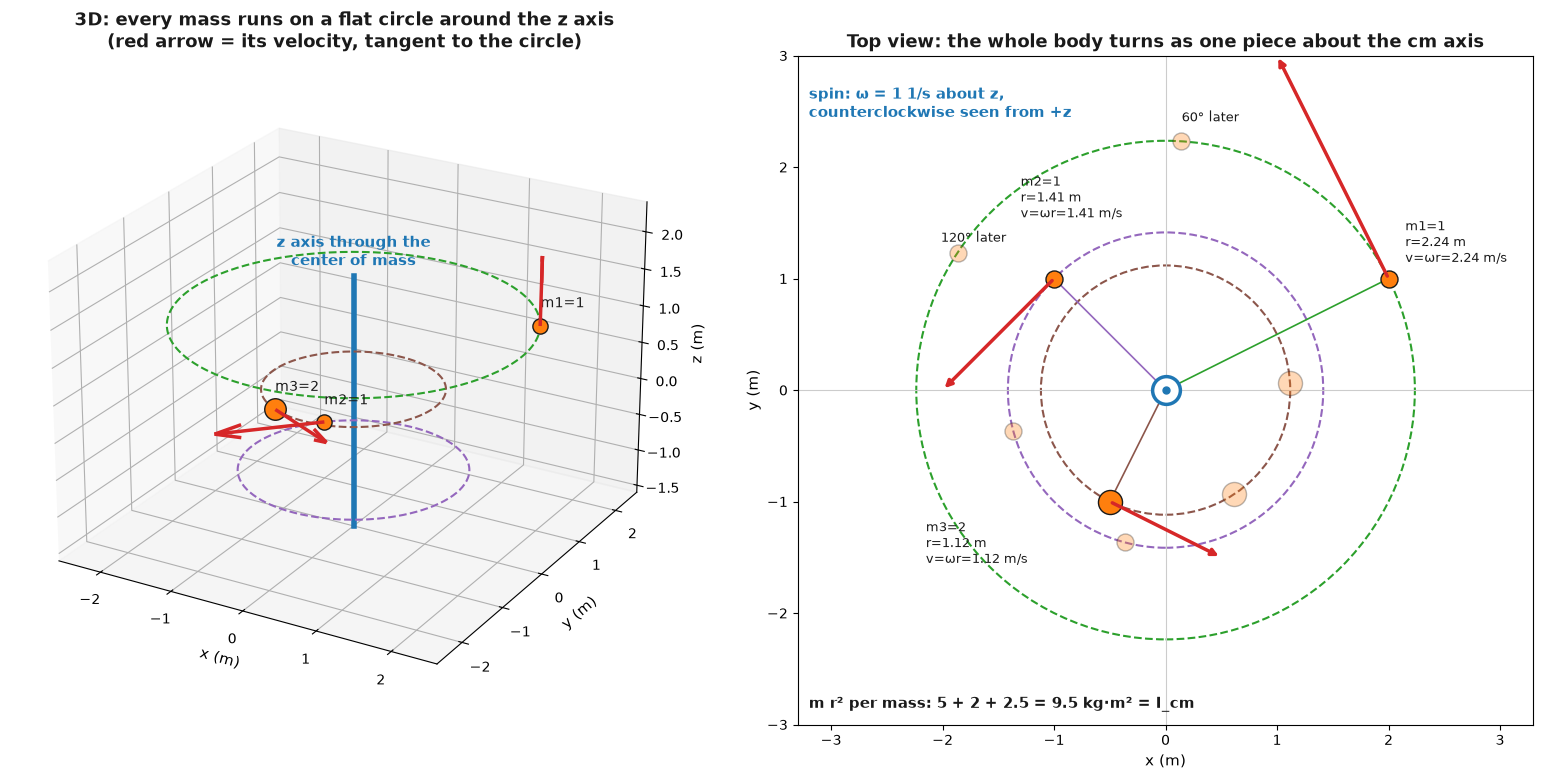

In [4]:
import os
from datetime import datetime
import numpy as np  # type: ignore
import matplotlib.pyplot as plt  # type: ignore

RESULT_DIR = os.path.join(os.getcwd(), "result")
os.makedirs(RESULT_DIR, exist_ok=True)
TIMESTAMP = datetime.now().strftime("%Y%m%d_%H%M%S")

# STEP 1: Body and spin
# What we have: 3 masses at (x_i, y_i, z_i), z axis through the center of mass (origin)
# What we want: see how every mass moves when the body spins about the z axis
# Why: this is the motion that I_cm measures the resistance to
# Formula: omega = (0, 0, W), velocity v_i = omega x r_i = W * (-y_i, x_i, 0)
m = np.array([1.0, 1.0, 2.0])
xy = np.array([[2.0, 1.0], [-1.0, 1.0], [-0.5, -1.0]])
z = np.array([1.2, -0.8, 0.3])
W = 1.0  # angular velocity about z (1/s)
assert np.allclose((m[:, None] * xy).sum(axis=0), 0)

# STEP 2: Radii, speeds, and each mass's share of I_cm
# What we have: xy, W
# What we want: r_i = |rho_i|, v_i = W r_i, m_i r_i^2
# Why: I_cm = sum m_i r_i^2 and kinetic energy = (1/2) I_cm W^2
r = np.linalg.norm(xy, axis=1)
v = np.column_stack([-W * xy[:, 1], W * xy[:, 0]])
speed = np.linalg.norm(v, axis=1)
share = m * r ** 2
I_cm = share.sum()
KE_parts = 0.5 * m * speed ** 2
print(f"I_cm={I_cm}, KE sum={KE_parts.sum()}, 0.5*I_cm*W^2={0.5*I_cm*W**2}")


def rot(p, a):
    c, s = np.cos(a), np.sin(a)
    return np.array([c * p[0] - s * p[1], s * p[0] + c * p[1]])


INK = "#1a1a1a"
C_CM, C_M, C_V = "#1f77b4", "#ff7f0e", "#d62728"
cols = ["#2ca02c", "#9467bd", "#8c564b"]
fig = plt.figure(figsize=(16, 7.5))

# STEP 3: 3D view, each mass moves on a flat circle around the z axis
# What we have: radius r_i and height z_i for each mass
# What we want: circle of radius r_i at height z_i, with the velocity arrow tangent to it
# Why: shows that height does not change the circle, only (x, y) sets the radius
a3 = fig.add_subplot(1, 2, 1, projection="3d")
zmin, zmax = -1.6, 1.8
a3.plot([0, 0], [0, 0], [zmin, zmax], color=C_CM, lw=4)
a3.text(0, 0, zmax + 0.15, "z axis through the\ncenter of mass", color=C_CM, fontsize=11, fontweight="bold", ha="center")
th = np.linspace(0, 2 * np.pi, 200)
for i in range(3):
    a3.plot(r[i] * np.cos(th + np.arctan2(xy[i, 1], xy[i, 0])), r[i] * np.sin(th + np.arctan2(xy[i, 1], xy[i, 0])),
            np.full_like(th, z[i]), color=cols[i], lw=1.5, ls="--")
    a3.scatter(*xy[i], z[i], s=120 * m[i], color=C_M, edgecolor=INK, depthshade=False, zorder=5)
    a3.quiver(xy[i, 0], xy[i, 1], z[i], v[i, 0], v[i, 1], 0, color=C_V, lw=2.5, arrow_length_ratio=0.25)
    a3.text(xy[i, 0], xy[i, 1], z[i] + 0.25, f"m{i+1}={m[i]:g}", fontsize=10, color=INK)
a3.set_xlabel("x (m)", fontsize=11)
a3.set_ylabel("y (m)", fontsize=11)
a3.set_zlabel("z (m)", fontsize=11)
a3.set_zlim(zmin, zmax + 0.6)
a3.set_xlim(-2.6, 2.6)
a3.set_ylim(-2.6, 2.6)
a3.view_init(elev=24, azim=-60)
a3.set_title("3D: every mass runs on a flat circle around the z axis\n(red arrow = its velocity, tangent to the circle)",
             fontsize=13, fontweight="bold", color=INK)

# STEP 4: Top view with snapshots of the spinning body
# What we have: positions, W
# What we want: the body at several angles (ghosts) plus the true circular paths
# Why: this is what "the body spins about the cm axis" looks like from above
ax = fig.add_subplot(1, 2, 2)
ax.set_aspect("equal")
ax.set_xlim(-3.3, 3.3)
ax.set_ylim(-3.0, 3.0)
ax.axhline(0, color="#cccccc", lw=0.8)
ax.axvline(0, color="#cccccc", lw=0.8)
for i in range(3):
    ax.add_patch(plt.Circle((0, 0), r[i], fill=False, ls="--", color=cols[i], lw=1.5))
for k, a in enumerate(np.deg2rad([60, 120])):
    pts = np.array([rot(p, a) for p in xy])
    for i in range(3):
        ax.scatter(*pts[i], s=150 * m[i], color=C_M, edgecolor=INK, alpha=0.3, zorder=2)
    ax.text(pts[0, 0] * 1.08, pts[0, 1] * 1.08, f"{int(round(np.rad2deg(a)))}° later", fontsize=9, color=INK)
for i in range(3):
    p = xy[i]
    ax.scatter(*p, s=150 * m[i], color=C_M, edgecolor=INK, zorder=5)
    ax.annotate("", xy=p + v[i], xytext=p, arrowprops=dict(arrowstyle="-|>", color=C_V, lw=2.5), zorder=6)
    ax.plot([0, p[0]], [0, p[1]], color=cols[i], lw=1.2, zorder=1)
    off = [(0.15, 0.15), (-0.3, 0.55), (-1.65, -0.55)][i]
    ax.text(p[0] + off[0], p[1] + off[1],
            f"m{i+1}={m[i]:g}\nr={r[i]:.2f} m\nv=ωr={speed[i]:.2f} m/s", fontsize=9.5, color=INK)
ax.plot(0, 0, "o", ms=20, mfc="white", mec=C_CM, mew=2.5, zorder=3)
ax.plot(0, 0, "o", ms=5, color=C_CM, zorder=4)
ax.annotate("", xy=(0.0, 3.0), xytext=(0, 3.0))
ax.text(-3.2, 2.45, "spin: ω = 1 1/s about z,\ncounterclockwise seen from +z", fontsize=11, fontweight="bold", color=C_CM)
ax.set_title("Top view: the whole body turns as one piece about the cm axis",
             fontsize=13, fontweight="bold", color=INK)
ax.set_xlabel("x (m)", fontsize=11)
ax.set_ylabel("y (m)", fontsize=11)
ax.text(-3.2, -2.85,
        "m r² per mass: " + " + ".join(f"{s:g}" for s in share) + f" = {I_cm:g} kg·m² = I_cm",
        fontsize=11, fontweight="bold", color=INK)

fig.tight_layout()
fig.savefig(os.path.join(RESULT_DIR, f"parallel_axis_cm_spin_{TIMESTAMP}.png"), dpi=140, bbox_inches="tight")
print("saved the figure")
plt.show()

I_new=29.5, KE=14.75, spin part=4.750000000000001, orbit part=10.000000000000002
v_cm = W*d = 2.24 m/s, I_cm + M d^2 = 29.500000000000007
saved the figure


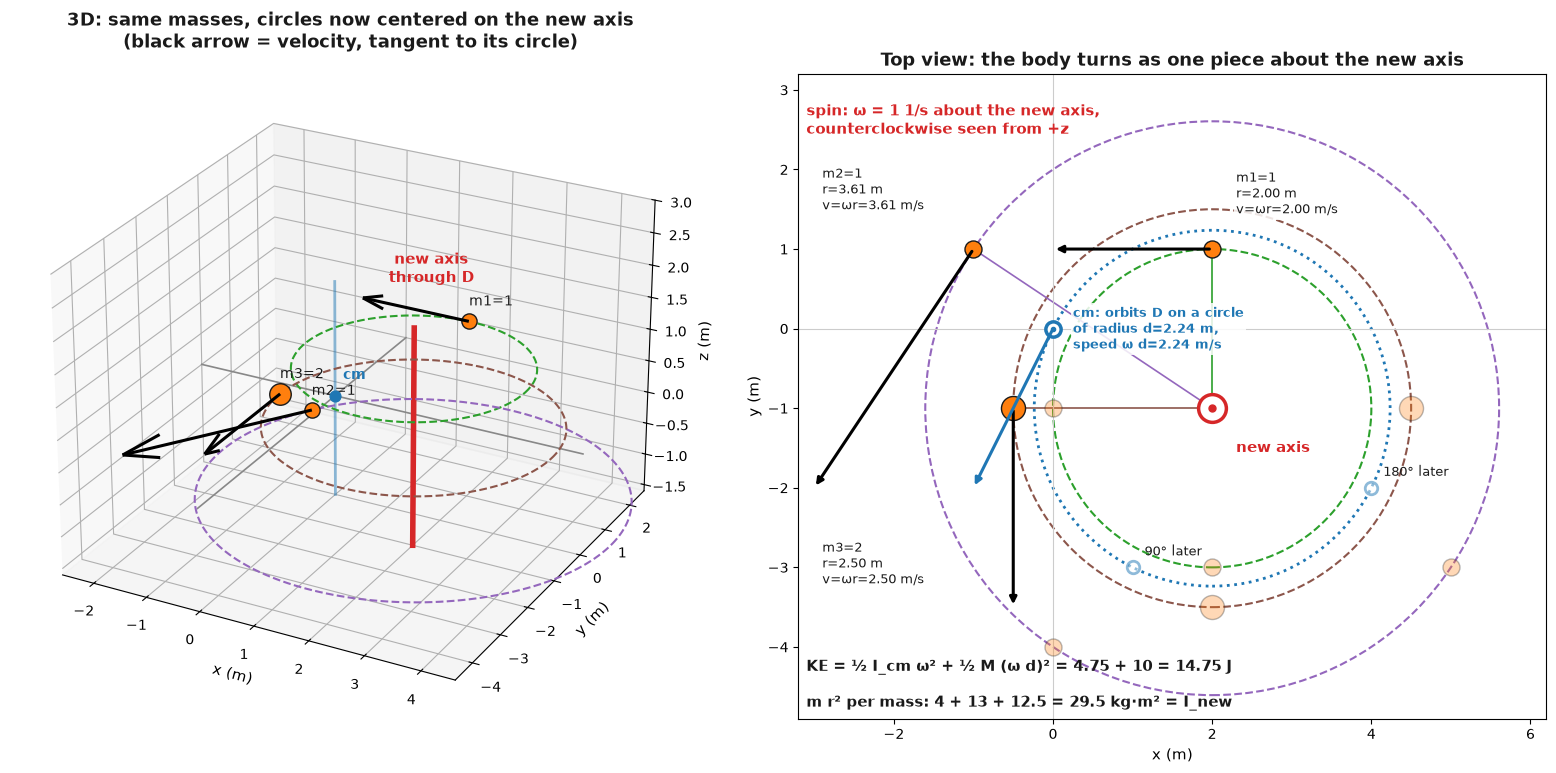

In [5]:
import os
from datetime import datetime
import numpy as np  # type: ignore
import matplotlib.pyplot as plt  # type: ignore

RESULT_DIR = os.path.join(os.getcwd(), "result")
os.makedirs(RESULT_DIR, exist_ok=True)
TIMESTAMP = datetime.now().strftime("%Y%m%d_%H%M%S")

# STEP 1: Same body, same mass locations, but the spin axis is now the one through D
# What we have: masses at (x_i, y_i, z_i), new vertical axis through D = (2, -1)
# What we want: how every mass moves when the body spins about the new axis
# Why: this is the motion that I_new measures the resistance to
# Formula: r_i = rho_i - D,  v_i = omega x r_i = W * (-r_iy, r_ix, 0)
m = np.array([1.0, 1.0, 2.0])
xy = np.array([[2.0, 1.0], [-1.0, 1.0], [-0.5, -1.0]])
z = np.array([1.2, -0.8, 0.3])
D = np.array([2.0, -1.0])
W = 1.0  # angular velocity about the new axis (1/s)
assert np.allclose((m[:, None] * xy).sum(axis=0), 0)

# STEP 2: Radii, speeds, shares of I_new, and the kinetic energy split
# What we have: xy, D, W
# What we want: |rho_i - D|, v_i, m_i r_i^2, and KE = 1/2 I_cm W^2 + 1/2 M (W d)^2
# Why: shows where the extra M d^2 comes from (the center of mass orbits the new axis)
rel = xy - D
r = np.linalg.norm(rel, axis=1)
v = np.column_stack([-W * rel[:, 1], W * rel[:, 0]])
speed = np.linalg.norm(v, axis=1)
share = m * r ** 2
I_new = share.sum()
M, d = m.sum(), np.linalg.norm(D)
I_cm = (m * np.linalg.norm(xy, axis=1) ** 2).sum()
KE_total = 0.5 * I_new * W ** 2
KE_spin = 0.5 * I_cm * W ** 2
KE_orbit = 0.5 * M * (W * d) ** 2
print(f"I_new={I_new}, KE={KE_total}, spin part={KE_spin}, orbit part={KE_orbit}")
print(f"v_cm = W*d = {W*d:.2f} m/s, I_cm + M d^2 = {I_cm + M*d**2}")


def rot_about(p, c, a):
    q = p - c
    cs, sn = np.cos(a), np.sin(a)
    return c + np.array([cs * q[0] - sn * q[1], sn * q[0] + cs * q[1]])


INK = "#1a1a1a"
C_CM, C_NEW, C_M, C_V = "#1f77b4", "#d62728", "#ff7f0e", "#000000"
cols = ["#2ca02c", "#9467bd", "#8c564b"]
fig = plt.figure(figsize=(16, 7.5))

# STEP 3: 3D view, circles now centered on the red axis
# What we have: r_i and z_i
# What we want: flat circle of radius r_i around the red axis at height z_i
# Why: same masses, new pivot line
a3 = fig.add_subplot(1, 2, 1, projection="3d")
zmin, zmax = -1.6, 1.8
a3.plot([-2.6, 4.6], [0, 0], [0, 0], color="#888888", lw=1.2)
a3.plot([0, 0], [-4.6, 2.6], [0, 0], color="#888888", lw=1.2)
a3.plot([0, 0], [0, 0], [zmin, zmax], color=C_CM, lw=2, alpha=0.5)
a3.plot([D[0]] * 2, [D[1]] * 2, [zmin, zmax], color=C_NEW, lw=4)
a3.text(D[0] + 0.3, D[1], zmax + 0.75, "new axis\nthrough D", color=C_NEW, fontsize=11, fontweight="bold", ha="center")
th = np.linspace(0, 2 * np.pi, 200)
for i in range(3):
    a3.plot(D[0] + r[i] * np.cos(th), D[1] + r[i] * np.sin(th), np.full_like(th, z[i]), color=cols[i], lw=1.5, ls="--")
    a3.scatter(*xy[i], z[i], s=120 * m[i], color=C_M, edgecolor=INK, depthshade=False, zorder=5)
    a3.quiver(xy[i, 0], xy[i, 1], z[i], v[i, 0], v[i, 1], 0, color=C_V, lw=2.2, arrow_length_ratio=0.2)
    a3.text(xy[i, 0], xy[i, 1], z[i] + 0.25, f"m{i+1}={m[i]:g}", fontsize=10, color=INK)
a3.scatter(0, 0, 0, s=60, color=C_CM, depthshade=False)
a3.text(0.1, 0.1, 0.25, "cm", color=C_CM, fontsize=10, fontweight="bold")
a3.set_xlabel("x (m)", fontsize=11)
a3.set_ylabel("y (m)", fontsize=11)
a3.set_zlabel("z (m)", fontsize=11)
a3.set_xlim(-2.6, 4.6)
a3.set_ylim(-4.6, 2.6)
a3.set_zlim(zmin, zmax + 1.2)
a3.view_init(elev=26, azim=-62)
a3.set_title("3D: same masses, circles now centered on the new axis\n(black arrow = velocity, tangent to its circle)",
             fontsize=13, fontweight="bold", color=INK)

# STEP 4: Top view with the body turning about D
# What we have: positions, D, W
# What we want: circles around D, velocities, and the center of mass orbiting D
# Why: the cm now travels on a circle of radius d, that is the extra M d^2
ax = fig.add_subplot(1, 2, 2)
ax.set_aspect("equal")
ax.set_xlim(-3.2, 6.2)
ax.set_ylim(-4.9, 3.2)
ax.axhline(0, color="#cccccc", lw=0.8)
ax.axvline(0, color="#cccccc", lw=0.8)
for i in range(3):
    ax.add_patch(plt.Circle(D, r[i], fill=False, ls="--", color=cols[i], lw=1.5))
ax.add_patch(plt.Circle(D, d, fill=False, ls=":", color=C_CM, lw=2))
for a in np.deg2rad([90, 180]):
    for i in range(3):
        ax.scatter(*rot_about(xy[i], D, a), s=150 * m[i], color=C_M, edgecolor=INK, alpha=0.3, zorder=2)
    c = rot_about(np.zeros(2), D, a)
    ax.plot(*c, "o", ms=9, mfc="white", mec=C_CM, mew=2, alpha=0.5)
    ax.text(c[0] + 0.15, c[1] + 0.15, f"{int(round(np.rad2deg(a)))}° later", fontsize=9, color=INK)
for i in range(3):
    p = xy[i]
    ax.scatter(*p, s=150 * m[i], color=C_M, edgecolor=INK, zorder=5)
    ax.annotate("", xy=p + v[i], xytext=p, arrowprops=dict(arrowstyle="-|>", color=C_V, lw=2.2), zorder=6)
    ax.plot([D[0], p[0]], [D[1], p[1]], color=cols[i], lw=1.2, zorder=1)
    off = [(0.3, 0.45), (-1.9, 0.5), (-2.4, -2.2)][i]
    ax.text(p[0] + off[0], p[1] + off[1],
            f"m{i+1}={m[i]:g}\nr={r[i]:.2f} m\nv=ωr={speed[i]:.2f} m/s", fontsize=9.5, color=INK, bbox=dict(fc="white", ec="none", alpha=0.85, pad=1.5), zorder=7)
ax.plot(*D, "o", ms=20, mfc="white", mec=C_NEW, mew=2.5, zorder=3)
ax.plot(*D, "o", ms=5, color=C_NEW, zorder=4)
ax.plot(0, 0, "o", ms=11, mfc="white", mec=C_CM, mew=2.5, zorder=3)
ax.plot(0, 0, "o", ms=3, color=C_CM, zorder=4)
vc = np.array([-W * (0 - D[1]), W * (0 - D[0])])
ax.annotate("", xy=vc, xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=C_CM, lw=2.2), zorder=6)
ax.text(0.25, -0.25, f"cm: orbits D on a circle\nof radius d={d:.2f} m,\nspeed ω d={W*d:.2f} m/s", fontsize=9.5,
        color=C_CM, fontweight="bold", bbox=dict(fc="white", ec="none", alpha=0.85, pad=1.5), zorder=7)
ax.text(D[0] + 0.3, D[1] - 0.55, "new axis", color=C_NEW, fontsize=11, fontweight="bold")
ax.text(-3.1, 2.45, "spin: ω = 1 1/s about the new axis,\ncounterclockwise seen from +z",
        fontsize=11, fontweight="bold", color=C_NEW)
ax.set_title("Top view: the body turns as one piece about the new axis",
             fontsize=13, fontweight="bold", color=INK)
ax.set_xlabel("x (m)", fontsize=11)
ax.set_ylabel("y (m)", fontsize=11)
ax.text(-3.1, -4.75,
        "m r² per mass: " + " + ".join(f"{s:g}" for s in share) + f" = {I_new:g} kg·m² = I_new",
        fontsize=11, fontweight="bold", color=INK)
ax.text(-3.1, -4.3,
        f"KE = ½ I_cm ω² + ½ M (ω d)² = {KE_spin:g} + {KE_orbit:g} = {KE_total:g} J",
        fontsize=11, fontweight="bold", color=INK)

fig.tight_layout()
fig.savefig(os.path.join(RESULT_DIR, f"parallel_axis_new_spin_{TIMESTAMP}.png"), dpi=140, bbox_inches="tight")
print("saved the figure")
plt.show()